In [1]:
import pandas as pd
import sqlite3 as sql

In [2]:
conn = sql.connect("data.db")

In [3]:
q = """SELECT * FROM sqlite_master """

pd.read_sql_query(q,conn)

,type,name,tbl_name,rootpage,sql
0,table,departments,departments,2,"CREATE TABLE ""departments"" (\n""department_id"" ..."
1,table,employees,employees,3,"CREATE TABLE ""employees"" (\n""employee_id"" INTE..."
2,table,customers,customers,6,"CREATE TABLE ""customers"" (\n""customer_id"" INTE..."
3,table,products,products,10,"CREATE TABLE ""products"" (\n""product_id"" INTEGE..."
4,table,orders,orders,11,"CREATE TABLE ""orders"" (\n""order_id"" INTEGER,\n..."
5,table,order_items,order_items,19,"CREATE TABLE ""order_items"" (\n""order_item_id"" ..."
6,table,order_insert_log,order_insert_log,30,CREATE TABLE order_insert_log (\n log_id IN...
7,table,sqlite_sequence,sqlite_sequence,31,"CREATE TABLE sqlite_sequence(name,seq)"
8,trigger,trg_order_insert,orders,0,CREATE TRIGGER trg_order_insert\nAFTER INSERT ...


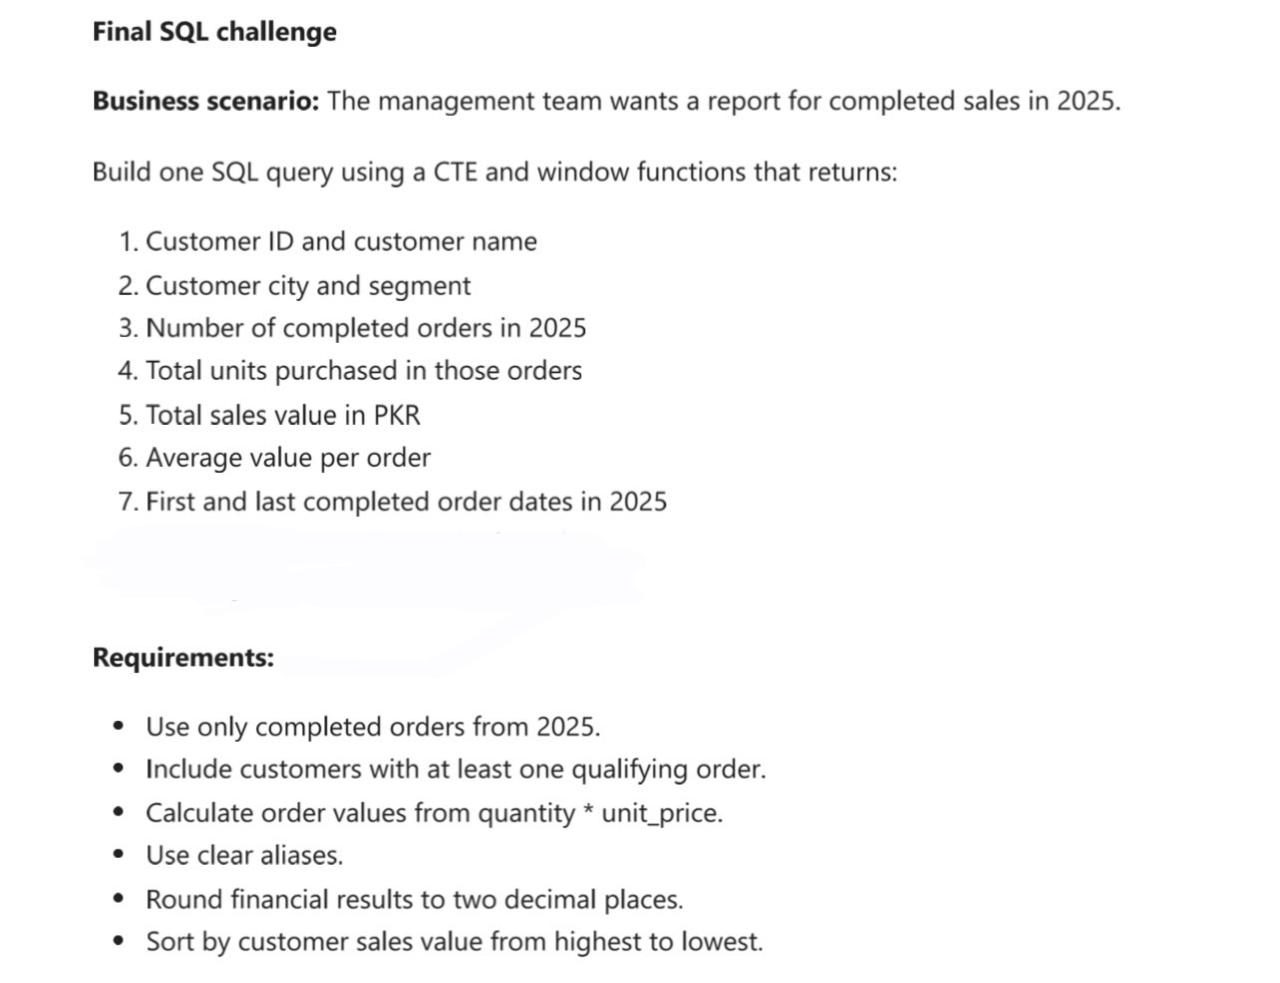

In [91]:
#3 Number of Completed orders in 2025

query = """SELECT COUNT(o.status) AS total_orders FROM orders o
        WHERE status = 'Completed' 
            AND order_date >= '2025-01-01'
            AND order_date <= '2025-12-31'
        """

pd.read_sql_query(query, conn)

,total_orders
0,114


In [105]:
#4 Total units purchased in those orders.

q = """SELECT 
        SUM(oi.quantity) AS total_items_purchased
        FROM orders o 
        JOIN order_items oi ON o.order_id = oi.order_id
        WHERE status = 'Completed' 
            AND order_date >= '2025-01-01'
            AND order_date <= '2025-12-31'
        """

pd.read_sql_query(q, conn)

,total_items_purchased
0,584


In [110]:
#5 TOTAL SALES VALUE IN PKR
q = """ SELECT (oi.quantity * oi.unit_price) AS total_sales_value_pkr
        FROM order_items oi
        """

pd.read_sql_query(q,conn)

,total_sales_value_pkr
0,140000
1,54880
2,18000
3,255000
4,49400
...,...
1266,18500
1267,44200
1268,625000
1269,58000


In [ ]:
# avg value per order

q = 

In [73]:

query = """SELECT c.customer_id, o.order_id, c.customer_name, c.city, c.customer_segment, o.status
         
        FROM customers c
        Join orders o ON c.customer_id=o.customer_id
        WHERE status = 'Completed' 
            
        """

pd.read_sql_query(query, conn)

,customer_id,order_id,customer_name,city,customer_segment,status
0,2080,4001,National Traders 080,Lahore,SME,Completed
1,2097,4002,Beta Distributors 097,Lahore,SME,Completed
2,2103,4004,Alpha Industries 103,Peshawar,SME,Completed
3,2049,4006,National Technologies 049,Karachi,Corporate,Completed
4,2134,4007,National Systems 134,Karachi,SME,Completed
...,...,...,...,...,...,...
282,2054,4493,Elite Enterprises 054,Karachi,Retail,Completed
283,2031,4494,Alpha Stores 031,Islamabad,Corporate,Completed
284,2009,4495,City Services 009,Karachi,Corporate,Completed
285,2017,4496,Royal Services 017,Faisalabad,SME,Completed
